In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from scipy.io.wavfile import read, write
freqEchan1, audio1 = read('Fichiers sonores de test-20251203/piano_mix.wav')

In [3]:
t_audio1 = np.arange(len(audio1))/freqEchan1

In [4]:
audio1Norm = audio1/10000

In [5]:
import IPython

IPython.display.Audio('Fichiers sonores de test-20251203/piano_mix.wav')

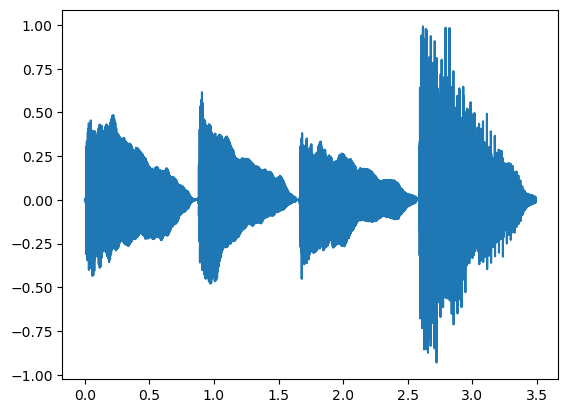

In [6]:
plt.plot(t_audio1, audio1Norm);

In [7]:
size = len(audio1)/30

In [8]:
from scipy.signal import stft
import scipy 

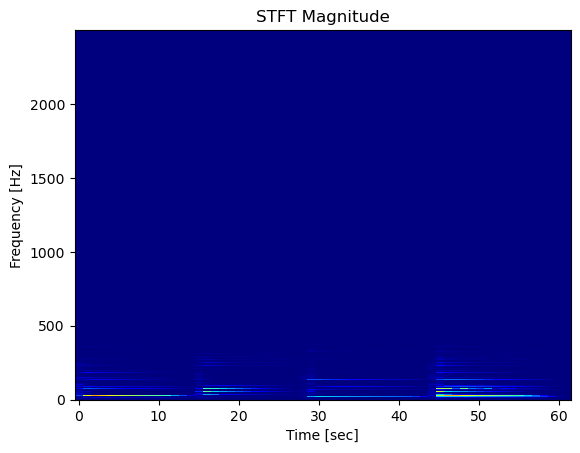

In [48]:
f, t, Zxx = stft(audio1, freqEchan1, nperseg=size)
plt.imshow(np.abs(Zxx[:2500]),aspect='auto', origin='lower', interpolation='nearest', cmap='jet')
plt.title('STFT Magnitude')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
plt.show()

In [55]:
amp = np.abs(Zxx)

In [56]:
from sklearn.decomposition import NMF

In [57]:
model = NMF(n_components=3, max_iter=2000, beta_loss=2)
W = model.fit_transform(amp)
H = model.components_

In [58]:
V = amp

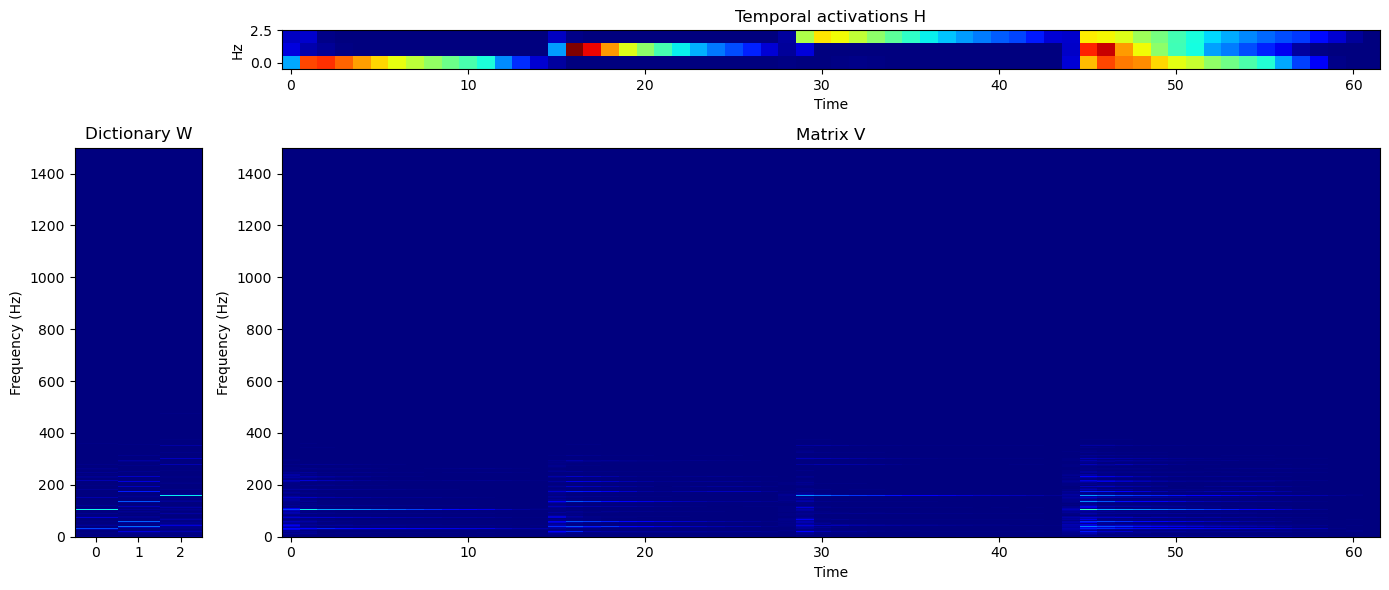

In [60]:
# --- FIGURE ---
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# -----------------------
#     MATRICE H (en haut)
# -----------------------
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(H, aspect='auto', origin='lower',interpolation='nearest', cmap='jet')
ax_H.set_title("Temporal activations H")
ax_H.set_ylabel("Hz")
ax_H.set_xlabel("Time")

# -----------------------
#       MATRICE W (gauche)
# -----------------------
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(W[:1500],aspect='auto', origin='lower', interpolation='nearest')
ax_W.set_title("Dictionary W")
ax_W.set_ylabel("Frequency (Hz)")

# -----------------------
# MATRICE V (spectrogramme)
# -----------------------
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.imshow(np.abs(Zxx)[:1500], aspect='auto', origin='lower', interpolation='nearest')
ax_V.set_title("Matrix V")
ax_V.set_xlabel("Time")
ax_V.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()